In [2]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
from astropy.timeseries import LombScargle
import warnings

warnings.filterwarnings('ignore')

# ----------------------------------------------------------------------------
# 1. CONFIGURATION
# ----------------------------------------------------------------------------
base_dir = r"ztffp_final_data_2025"
csv_meta_path = r"wu_shen_selected_columns.csv"

# Focando apenas na banda G conforme solicitado
BANDS_TO_PROCESS = ['g'] 

MIN_CADENCE_DAYS = 12.0
SEASON_GAP_DAYS = 100.0
MAX_INTERP_FRACTION = 0.15
MAX_CONSECUTIVE_GAPS = 3
f_max_nyquist = 1.0 / (2.0 * MIN_CADENCE_DAYS)
f_season_cutoff = 1.0 / SEASON_GAP_DAYS

Z_MIN, Z_MAX = 0.4, 0.5
mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5]

N_BINS_FREQ = 40
MIN_OBJS_PER_BIN = 50
N_BOOTSTRAP = 200

cmap = plt.get_cmap('tab10')

# ----------------------------------------------------------------------------
# 2. CORE FUNCTIONS (Matemática e PSD)
# ----------------------------------------------------------------------------

def build_season_grid(t_s, f_s, f_err_s, cadence_days=MIN_CADENCE_DAYS):
    if len(t_s) < 4: return None, None, None, 1.0
    t_start, t_end = t_s.min(), t_s.max()
    n_bins = int(np.floor((t_end - t_start) / cadence_days)) + 1
    if n_bins < 2: return None, None, None, 1.0
        
    t_grid = t_start + (np.arange(n_bins) + 0.5) * cadence_days
    f_grid = np.full(n_bins, np.nan)
    f_err_grid = np.full(n_bins, np.nan)
    
    for i in range(n_bins):
        lo = t_start + i * cadence_days
        hi = lo + cadence_days
        in_bin = (t_s >= lo) & (t_s < hi)
        if i == n_bins - 1:
            in_bin = (t_s >= lo) & (t_s <= hi + 1e-6)
            
        n_in = np.sum(in_bin)
        if n_in > 0:
            f_grid[i] = np.mean(f_s[in_bin])
            if n_in > 1:
                f_err_grid[i] = np.std(f_s[in_bin], ddof=1) / np.sqrt(n_in)
            else:
                f_err_grid[i] = f_err_s[in_bin][0]
    
    frac_empty = np.sum(np.isnan(f_grid)) / n_bins
    if frac_empty > MAX_INTERP_FRACTION: return None, None, None, frac_empty
        
    cons, max_cons = 0, 0
    for v in f_grid:
        if np.isnan(v):
            cons += 1
            max_cons = max(max_cons, cons)
        else:
            cons = 0
    if max_cons > MAX_CONSECUTIVE_GAPS: return None, None, None, frac_empty
        
    valid = ~np.isnan(f_grid)
    if np.sum(valid) < 2: return None, None, None, 1.0
        
    f_grid_interp = np.interp(t_grid, t_grid[valid], f_grid[valid])
    var_interp = np.interp(t_grid, t_grid[valid], f_err_grid[valid]**2)
    f_err_interp = np.sqrt(var_interp)
    f_grid_interp = f_grid_interp - np.mean(f_grid_interp)
    
    return t_grid, f_grid_interp, f_err_interp, frac_empty


def compute_fft_psd(t_grid, f_grid, cadence_days=MIN_CADENCE_DAYS):
    N = len(t_grid)
    if N < 4: return None, None
    fft = np.fft.rfft(f_grid)
    freqs = np.fft.rfftfreq(N, d=cadence_days)[1:]
    power = (np.abs(fft[1:]) ** 2) * (2.0 * cadence_days / N)
    return freqs, power


def compute_low_freq_psd_seasonal(seasons_t, seasons_f, seasons_f_err, cadence_days=MIN_CADENCE_DAYS):
    if len(seasons_t) < 2: return None, None
    t_means = np.array([np.mean(ts) for ts in seasons_t])
    f_means = np.array([np.mean(fs) for fs in seasons_f])
    order = np.argsort(t_means)
    t_means, f_means = t_means[order], f_means[order]
    
    t_start, t_end = t_means.min(), t_means.max()
    n_bins = int(np.floor((t_end - t_start) / cadence_days)) + 1
    if n_bins < 4: return None, None
        
    t_grid = t_start + np.arange(n_bins) * cadence_days
    f_interp = np.interp(t_grid, t_means, f_means)
    f_interp = f_interp - np.mean(f_interp)
    
    freqs, power = compute_fft_psd(t_grid, f_interp, cadence_days)
    if freqs is None: return None, None
    mask = freqs < f_season_cutoff
    return freqs[mask], power[mask]


def compute_high_freq_psd(seasons_t, seasons_f, seasons_f_err):
    all_f, all_p = [], []
    for t_s, f_s, f_err_s in zip(seasons_t, seasons_f, seasons_f_err):
        result = build_season_grid(t_s, f_s - np.mean(f_s), f_err_s)
        if result[0] is None: continue
        t_grid, f_grid, _, _ = result
        freqs, power = compute_fft_psd(t_grid, f_grid)
        if freqs is not None:
            all_f.extend(freqs); all_p.extend(power)
    if not all_f: return None, None
    return np.array(all_f), np.array(all_p)


def bin_psd_to_grid(freqs, powers, bin_edges):
    n_bins = len(bin_edges) - 1
    binned = np.full(n_bins, np.nan)
    inds = np.searchsorted(bin_edges, freqs, side='right') - 1
    valid = (inds >= 0) & (inds < n_bins)
    if not np.any(valid): return binned
    bid, pw = inds[valid], powers[valid]
    sums = np.bincount(bid, weights=pw, minlength=n_bins)
    counts = np.bincount(bid, minlength=n_bins)
    mask = counts > 0
    binned[mask] = sums[mask] / counts[mask]
    return binned


def bending_pl_petrecca(f, PSD_norm, nu_b, alpha_high, C_noise):
    alpha_diff = -1.0 - alpha_high
    term = (1.0 + (f / nu_b)**alpha_diff)**(-1)
    return PSD_norm * (f**(-1.0)) * term + C_noise


def fit_bending_pl_petrecca(freq, power, fix_alpha_high=None):
    mask = (power > 0) & np.isfinite(power) & np.isfinite(freq) & (freq > 0)
    if np.sum(mask) < 5: return None
    f_fit, p_fit = freq[mask], power[mask]

    try:
        if fix_alpha_high is None:
            p0 = [np.median(p_fit * f_fit), 1e-3, -2.7, np.min(p_fit) * 0.1]
            bounds = ([1e-10, 1e-6, -5.0, 0], [10.0, 0.1, -1.0, np.max(p_fit)])
            popt, _ = curve_fit(bending_pl_petrecca, f_fit, p_fit, p0=p0, bounds=bounds, maxfev=5000)
            return {'PSD_norm': popt[0], 'nu_b': popt[1], 'alpha_high': popt[2], 'C_noise': popt[3]}
        else:
            def model_fixed(f, PSD_norm, nu_b, C_noise):
                return bending_pl_petrecca(f, PSD_norm, nu_b, fix_alpha_high, C_noise)
            p0 = [np.median(p_fit * f_fit), 1e-3, np.min(p_fit) * 0.1]
            bounds = ([1e-10, 1e-6, 0], [10.0, 0.1, np.max(p_fit)])
            popt, _ = curve_fit(model_fixed, f_fit, p_fit, p0=p0, bounds=bounds, maxfev=5000)
            return {'PSD_norm': popt[0], 'nu_b': popt[1], 'alpha_high': fix_alpha_high, 'C_noise': popt[2]}
    except Exception:
        return None


def bootstrap_psd(matrix, n_boot=N_BOOTSTRAP):
    n = matrix.shape[0]
    if n < 2: return np.nanmedian(matrix, axis=0), np.zeros(matrix.shape[1])
    samples = []
    for _ in range(n_boot):
        idx = np.random.choice(n, size=n, replace=True)
        samples.append(np.nanmedian(matrix[idx, :], axis=0))
    samples = np.array(samples)
    return np.nanmedian(samples, axis=0), np.nanstd(samples, axis=0)


# ----------------------------------------------------------------------------
# 3. NOVAS FUNÇÕES DE PLOTAGEM (As 3 figuras solicitadas)
# ----------------------------------------------------------------------------

def plot_distribution_grid(LOGMBH_arr, LOGLEDD_arr, band):
    """Figura 1: Grid de Massa vs EDDR com o número de objetos."""
    fig, ax = plt.subplots(figsize=(10, 8))
    
    H, xedges, yedges = np.histogram2d(LOGMBH_arr, LOGLEDD_arr, bins=(mass_edges, edd_edges))
    X, Y = np.meshgrid(xedges, yedges)
    
    # Mapa de calor
    pc = ax.pcolormesh(X, Y, H.T, cmap='Blues', edgecolors='black', linewidth=1, alpha=0.8)
    
    # Adicionar o texto com as contagens
    for i in range(len(mass_edges)-1):
        for j in range(len(edd_edges)-1):
            count = int(H[i, j])
            if count > 0:
                # Cor do texto adapta-se ao fundo escuro/claro
                color = 'white' if count > np.max(H)/2 else 'black'
                ax.text((mass_edges[i] + mass_edges[i+1])/2, 
                        (edd_edges[j] + edd_edges[j+1])/2, 
                        str(count), ha='center', va='center', 
                        color=color, fontweight='bold', fontsize=12)
    
    ax.set_xlabel(r'$\log M_{\rm BH}$', fontweight='bold', fontsize=14)
    ax.set_ylabel(r'$\log \lambda_{\rm Edd}$', fontweight='bold', fontsize=14)
    ax.set_title(f'Object Distribution (Band {band.upper()})', fontweight='bold', fontsize=16)
    ax.set_xticks(mass_edges)
    ax.set_yticks(edd_edges)
    
    cbar = plt.colorbar(pc, ax=ax)
    cbar.set_label('Number of Objects', fontweight='bold', fontsize=12)
    
    plt.tight_layout()
    plt.savefig(f'Grid_Mass_Edd_band_{band}.png', dpi=200)
    plt.close()


def plot_ensemble_split(LOGMBH_arr, LOGLEDD_arr, binned_matrix_fft, binned_matrix_ls, bin_centers, band, grouping='Mass'):
    """Figuras 2 e 3: PSD lado a lado (Petrecca vs Lomb-Scargle) por grupo."""
    fig, (ax_fft, ax_ls) = plt.subplots(1, 2, figsize=(20, 8), sharey=True)
    
    mi = np.digitize(LOGMBH_arr, mass_edges) - 1
    ej = np.digitize(LOGLEDD_arr, edd_edges) - 1
    valid = ((mi >= 0) & (mi < len(mass_edges)-1) & (ej >= 0) & (ej < len(edd_edges)-1))
    
    if grouping == 'Mass':
        groups = range(len(mass_edges)-1); arr = mi; prefix = 'BH Mass'
    else:
        groups = range(len(edd_edges)-1); arr = ej; prefix = 'Eddington Ratio'

    fit_results = []

    for i, g in enumerate(groups):
        mask = valid & (arr == g)
        idxs = np.where(mask)[0]
        if len(idxs) < MIN_OBJS_PER_BIN: continue
        
        color = cmap(i % cmap.N)
        lbl = (f"{mass_edges[g]:.1f}-{mass_edges[g+1]:.1f} | N={len(idxs)}" 
               if grouping == 'Mass' else 
               f"{edd_edges[g]:.1f} to {edd_edges[g+1]:.1f} | N={len(idxs)}")
        
        # --- LADO ESQUERDO: FFT (Petrecca) ---
        sub_fft = binned_matrix_fft[idxs, :]
        good_fft = np.sum(~np.isnan(sub_fft), axis=0) >= max(3, len(idxs)//10)
        if np.sum(good_fft) >= 4:
            med_fft, std_fft = bootstrap_psd(sub_fft[:, good_fft])
            x_f = bin_centers[good_fft]
            
            ax_fft.loglog(x_f, med_fft, 'o-', color=color, lw=2, ms=5, label=lbl)
            ax_fft.fill_between(x_f, np.maximum(med_fft - std_fft, 1e-12), med_fft + std_fft, color=color, alpha=0.2)
            
            fit_free = fit_bending_pl_petrecca(x_f, med_fft, fix_alpha_high=None)
            if fit_free:
                f_th = np.logspace(np.log10(x_f.min()), np.log10(x_f.max()), 100)
                p_th = bending_pl_petrecca(f_th, fit_free['PSD_norm'], fit_free['nu_b'], fit_free['alpha_high'], fit_free['C_noise'])
                ax_fft.loglog(f_th, p_th, '--', color=color, alpha=0.8, lw=1.5)
                
                fit_results.append({
                    'grouping': grouping, 'bin': int(g), 'N_objects': int(len(idxs)),
                    'center': float(np.median(LOGMBH_arr[mask])) if grouping=='Mass' else float(np.median(LOGLEDD_arr[mask])),
                    'method': 'FFT', 'nu_b': float(fit_free['nu_b']), 'alpha_high': float(fit_free['alpha_high']), 
                    'PSD_norm': float(fit_free['PSD_norm']), 'C_noise': float(fit_free['C_noise'])
                })

        # --- LADO DIREITO: Lomb-Scargle ---
        sub_ls = binned_matrix_ls[idxs, :]
        good_ls = np.sum(~np.isnan(sub_ls), axis=0) >= max(3, len(idxs)//10)
        if np.sum(good_ls) >= 4:
            med_ls, std_ls = bootstrap_psd(sub_ls[:, good_ls])
            x_f_ls = bin_centers[good_ls]
            
            ax_ls.loglog(x_f_ls, med_ls, 's-', color=color, lw=2, ms=5, label=lbl)
            ax_ls.fill_between(x_f_ls, np.maximum(med_ls - std_ls, 1e-12), med_ls + std_ls, color=color, alpha=0.2)
            
            fit_ls = fit_bending_pl_petrecca(x_f_ls, med_ls, fix_alpha_high=None)
            if fit_ls:
                f_th_ls = np.logspace(np.log10(x_f_ls.min()), np.log10(x_f_ls.max()), 100)
                p_th_ls = bending_pl_petrecca(f_th_ls, fit_ls['PSD_norm'], fit_ls['nu_b'], fit_ls['alpha_high'], fit_ls['C_noise'])
                ax_ls.loglog(f_th_ls, p_th_ls, ':', color=color, alpha=0.8, lw=1.5)
                
                fit_results.append({
                    'grouping': grouping, 'bin': int(g), 'N_objects': int(len(idxs)),
                    'center': float(np.median(LOGMBH_arr[mask])) if grouping=='Mass' else float(np.median(LOGLEDD_arr[mask])),
                    'method': 'LS', 'nu_b': float(fit_ls['nu_b']), 'alpha_high': float(fit_ls['alpha_high']), 
                    'PSD_norm': float(fit_ls['PSD_norm']), 'C_noise': float(fit_ls['C_noise'])
                })

    # Legenda customizada para os ajustes
    handles_fft, labels_fft = ax_fft.get_legend_handles_labels()
    handles_fft.append(Line2D([0], [0], color='gray', lw=2, ls='--'))
    labels_fft.append('BPL Fit')
    ax_fft.legend(handles_fft, labels_fft, fontsize=10, loc='lower left')
    
    handles_ls, labels_ls = ax_ls.get_legend_handles_labels()
    handles_ls.append(Line2D([0], [0], color='gray', lw=2, ls=':'))
    labels_ls.append('BPL Fit')
    ax_ls.legend(handles_ls, labels_ls, fontsize=10, loc='lower left')

    ax_fft.set_xlabel(r'Frequency [day$^{-1}$]', fontweight='bold', fontsize=12)
    ax_fft.set_ylabel('Power', fontweight='bold', fontsize=12)
    ax_fft.set_title(f'{prefix} - Petrecca like Method (FFT)', fontweight='bold', fontsize=14)
    ax_fft.grid(ls=':', alpha=0.5, which='both')

    ax_ls.set_xlabel(r'Frequency [day$^{-1}$]', fontweight='bold', fontsize=12)
    ax_ls.set_title(f'{prefix} - Lomb-Scargle', fontweight='bold', fontsize=14)
    ax_ls.grid(ls=':', alpha=0.5, which='both')

    plt.suptitle(f"Ensemble PSD Comparison (Band {band.upper()})", fontweight='bold', fontsize=18)
    plt.tight_layout()
    plt.savefig(f'Ensemble_Comparison_{grouping}_band_{band}.png', dpi=200)
    plt.close()
    
    return fit_results


# ----------------------------------------------------------------------------
# 4. MAIN PIPELINE
# ----------------------------------------------------------------------------

for band in BANDS_TO_PROCESS:
    print(f"\n{'='*60}")
    print(f" STARTING PROCESSING FOR BAND: '{band.upper()}'")
    print(f"{'='*60}")

    plots_dir = f"plots_Petrecca_Corrected_band_{band}"
    os.makedirs(plots_dir, exist_ok=True)

    print("Loading metadata...")
    try:
        meta = pd.read_csv(csv_meta_path.replace("\\", "/"))
        ra_cat = meta['RA'].values
        dec_cat = meta['DEC'].values
        logmbh_cat = meta['LOGMBH'].values
        logedd_cat = meta['LOGLEDD_RATIO'].values
        z_col = 'Z_DR16Q' if 'Z_DR16Q' in meta.columns else 'Z'
        z_cat = meta[z_col].values
    except FileNotFoundError:
        print(f"WARNING: Metadata catalog {csv_meta_path} not found.")
        continue

    folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and "plots" not in f]
    valid_data = []
    n_rej_interp = n_rej_seasons = n_rej_other = 0

    for folder in tqdm(folders, desc=f"Band {band}"):
        try:
            ra_f, dec_f = map(float, folder.split('_'))
        except:
            continue
        dist = np.sqrt((ra_cat - ra_f)**2 + (dec_cat - dec_f)**2)
        idx = np.argmin(dist)
        if dist[idx] > 1e-4: continue
        
        m, e, z = logmbh_cat[idx], logedd_cat[idx], z_cat[idx]
        if np.isnan(m) or np.isnan(e) or np.isnan(z): continue
        if z < Z_MIN or z > Z_MAX: continue
        if m < mass_edges[0] or m >= mass_edges[-1]: continue
        if e < edd_edges[0] or e >= edd_edges[-1]: continue
        
        txt_files = glob.glob(os.path.join(base_dir, folder, f"*_ztf_{band}_filtered.txt"))
        if not txt_files: continue
        
        try:
            df = pd.read_csv(txt_files[0]).sort_values('mjd')
            if len(df) < 20 or 'mjd' not in df.columns or 'flux' not in df.columns: continue
            
            t_obs = df['mjd'].values
            f_obs = df['flux'].values
            f_err = df['fluxe'].values if 'fluxe' in df.columns else np.zeros_like(f_obs)

            t_ref = t_obs.min()
            t_rest = (t_obs - t_ref) / (1.0 + z)
            T_total_rest = t_rest.max() - t_rest.min()

            f_med = np.median(f_obs)
            f_norm = (f_obs - f_med) / f_med
            f_err_norm = f_err / f_med

            gaps = np.diff(t_rest)
            breaks = np.where(gaps > SEASON_GAP_DAYS / (1.0 + z))[0] + 1
            season_idx = np.split(np.arange(len(t_rest)), breaks)

            seasons_t, seasons_f, seasons_f_err = [], [], []
            for s in season_idx:
                if len(s) > 3:
                    ts_, fs_, ferr_ = t_rest[s], f_norm[s], f_err_norm[s]
                    result = build_season_grid(ts_, fs_ - np.mean(fs_), ferr_)
                    if result[0] is None:
                        n_rej_interp += 1
                        continue
                    seasons_t.append(ts_)
                    seasons_f.append(fs_)
                    seasons_f_err.append(ferr_)

            if len(seasons_t) < 2:
                n_rej_seasons += 1
                continue

            valid_data.append({
                't_obs': t_obs, 't_rest': t_rest,
                'flux_norm': f_norm, 'flux_err_norm': f_err_norm,
                'seasons_t': seasons_t, 
                'seasons_f_norm': seasons_f,
                'seasons_f_err': seasons_f_err,
                'T_total': T_total_rest,
                'LOGMBH': m, 'LOGLEDD_RATIO': e, 'Z': z
            })
        except Exception:
            n_rej_other += 1
            continue

    print(f"Total valid: {len(valid_data)}")
    if not valid_data: continue

    # --- Grade de Frequências ---
    global_fmin = 1.0 / max([d['T_total'] for d in valid_data])
    bin_edges = np.logspace(np.log10(global_fmin), np.log10(f_max_nyquist), N_BINS_FREQ + 1)
    bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

    binned_matrix_fft = np.full((len(valid_data), N_BINS_FREQ), np.nan)
    binned_matrix_ls = np.full((len(valid_data), N_BINS_FREQ), np.nan)

    for i, d in enumerate(valid_data):
        # Lomb-Scargle
        try:
            ls = LombScargle(d['t_rest'], d['flux_norm'], dy=d['flux_err_norm'])
            # Usa 'standard' (que é independente de N) e depois converte para PSD
            f_ls, p_ls_standard = ls.autopower(normalization='standard', maximum_frequency=f_max_nyquist)

            # O fator de conversão para a densidade espectral equivalente à FFT é:
            # PSD = (2 * P_standard * variância) / (N * frequência_media)
            variance = np.var(d['flux_norm'])
            N_points = len(d['t_rest'])
            delta_f = f_ls[1] - f_ls[0]  # Passo em frequência

            # Converte para a mesma escala da FFT
            p_ls_psd = (2.0 * p_ls_standard * variance) / (N_points * delta_f)

            binned_matrix_ls[i, :] = bin_psd_to_grid(f_ls, p_ls_psd, bin_edges)
        except Exception:
            pass

        # FFT Dual-Timescale
        f_hi, p_hi = compute_high_freq_psd(d['seasons_t'], d['seasons_f_norm'], d['seasons_f_err'])
        f_lo, p_lo = compute_low_freq_psd_seasonal(d['seasons_t'], d['seasons_f_norm'], d['seasons_f_err'])
        parts_f, parts_p = [], []
        if f_lo is not None: parts_f.append(f_lo); parts_p.append(p_lo)
        if f_hi is not None: parts_f.append(f_hi); parts_p.append(p_hi)
        if parts_f:
            binned_matrix_fft[i, :] = bin_psd_to_grid(np.concatenate(parts_f), np.concatenate(parts_p), bin_edges)

    LOGMBH_arr = np.array([d['LOGMBH'] for d in valid_data])
    LOGLEDD_arr = np.array([d['LOGLEDD_RATIO'] for d in valid_data])

    # --- GERAR AS 3 FIGURAS SOLICITADAS ---
    
    # 1. Grid de distribuição com contagens
    print("Generating Figure 1: Object Distribution Grid...")
    plot_distribution_grid(LOGMBH_arr, LOGLEDD_arr, band)
    
    # 2. Comparação PSD por Massa
    print("Generating Figure 2: Ensemble PSD by Mass (Split)...")
    fits_mass = plot_ensemble_split(LOGMBH_arr, LOGLEDD_arr, binned_matrix_fft, binned_matrix_ls, bin_centers, band, grouping='Mass')
    
    # 3. Comparação PSD por Eddington
    print("Generating Figure 3: Ensemble PSD by Eddington (Split)...")
    fits_edd = plot_ensemble_split(LOGMBH_arr, LOGLEDD_arr, binned_matrix_fft, binned_matrix_ls, bin_centers, band, grouping='Eddington')

    # --- Salvar Resultados ---
    all_fits = fits_mass + fits_edd
    if all_fits:
        df_fits = pd.DataFrame(all_fits)
        df_fits.to_csv(os.path.join(plots_dir, f'Fit_results_Comparison_band_{band}.csv'), index=False)
        print(f"Results saved to {plots_dir}/Fit_results_Comparison_band_{band}.csv")

print("\n=== PROCESSING COMPLETE ===")


 STARTING PROCESSING FOR BAND: 'G'
Loading metadata...


Band g: 100%|██████████| 2261/2261 [00:42<00:00, 52.69it/s]


Total valid: 1933
Generating Figure 1: Object Distribution Grid...
Generating Figure 2: Ensemble PSD by Mass (Split)...
Generating Figure 3: Ensemble PSD by Eddington (Split)...
Results saved to plots_Petrecca_Corrected_band_g/Fit_results_Comparison_band_g.csv

=== PROCESSING COMPLETE ===


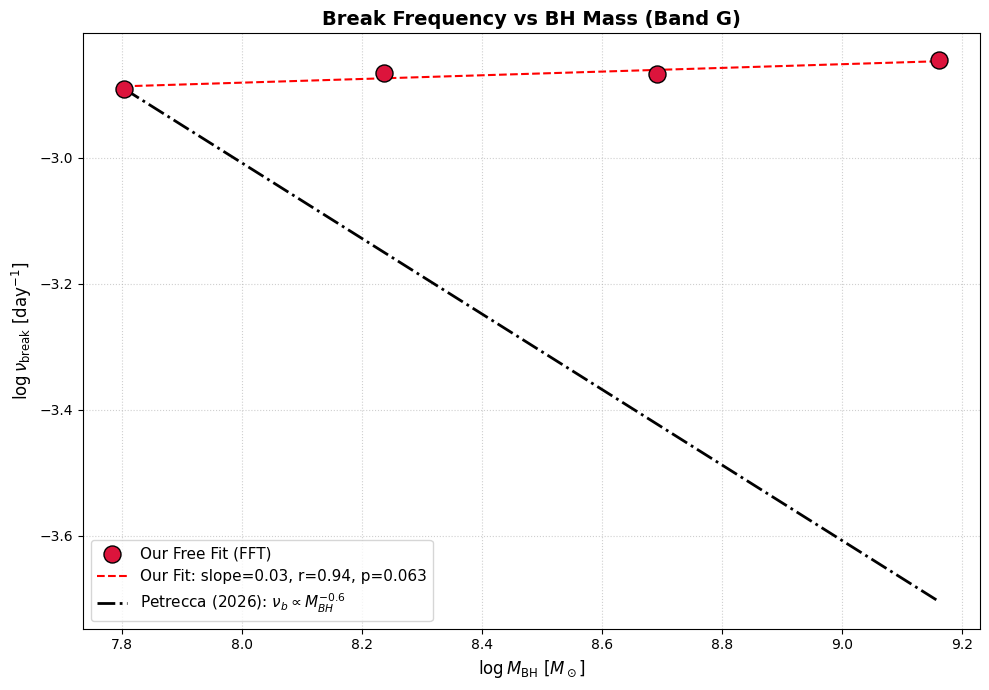

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Carregar os resultados salvos pelo pipeline anterior
# (Garanta que o caminho está correto)
df = pd.read_csv('plots_Petrecca_Corrected_band_g/Fit_results_Comparison_band_g.csv')

# Filtrar apenas os resultados por Massa e do método FFT
df_mass = df[(df['grouping'] == 'Mass') & (df['method'] == 'FFT')]

if not df_mass.empty:
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # Nossos dados
    mass = df_mass['center']
    log_nub_free = np.log10(df_mass['nu_b'])
    ax.scatter(mass, log_nub_free, s=150, c='crimson', edgecolor='black', zorder=3, label='Our Free Fit (FFT)')
    
    # Nossa tendência
    coef = np.polyfit(mass, log_nub_free, 1)
    r, p = pearsonr(mass, log_nub_free)
    xs = np.linspace(mass.min(), mass.max(), 100)
    ax.plot(xs, np.polyval(coef, xs), 'r--', label=f'Our Fit: slope={coef[0]:.2f}, r={r:.2f}, p={p:.3f}')

    # Adicionar a previsão do Petrecca (nu_b ~ M^-0.6)
    # Vamos ancorar a linha do Petrecca no centro do nosso primeiro ponto para comparar inclinações
    anchor_x = mass.iloc[0]
    anchor_y = log_nub_free.iloc[0]
    # log(nu_b) = log(nu_b0) - 0.6 * (logM - logM0)
    petrecca_slope = -0.6
    petrecca_line = anchor_y + petrecca_slope * (xs - anchor_x)
    
    ax.plot(xs, petrecca_line, 'k-.', lw=2, label='Petrecca (2026): $\\nu_b \propto M_{BH}^{-0.6}$')
    
    ax.set_xlabel(r'$\log M_{\rm BH} \ [M_\odot]$', fontweight='bold', fontsize=12)
    ax.set_ylabel(r'$\log \nu_{\rm break} \ [\mathrm{day}^{-1}]$', fontweight='bold', fontsize=12)
    ax.set_title('Break Frequency vs BH Mass (Band G)', fontweight='bold', fontsize=14)
    ax.legend(fontsize=11)
    ax.grid(ls=':', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig('Compare_Petrecca_Mass_Nub.png', dpi=200)
    plt.show()
else:
    print("Nenhum resultado de FFT por massa encontrado no CSV.")